# CS4048: Data Science — Assignment 2: Exploratory Data Analysis
**Student Name:** Muhammad Waqar Saleem  
**Roll Number:** 23L-1021  
**Section:** BCS-7A  

---

### Dataset Publication & Versioning Links
* **Part A (Netflix Cleaned):** [Insert GitHub Release / Kaggle URL here | Version: v1.0]
* **Part B (Supermarket Sales Cleaned):** [Insert GitHub Release / Kaggle URL here | Version: v1.0]
* **Repository Link:** [Insert Public Repository Link]

---

In [1]:
# Cell 1: Standard scientific and data analysis stack (strictly permitted libraries)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import statsmodels.api as sm

# Configure visual styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_palette('muted')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11

# Suppress unnecessary pandas chained assignment warnings
pd.options.mode.chained_assignment = None

print("Libraries imported successfully.")

Libraries imported successfully.


# Part A: Netflix Movies and TV Shows EDA

---

## A1. Dataset Understanding

In [5]:
# Cell 2: Load the Netflix dataset
netflix_path = 'data/netflix_titles.csv' 
df_netflix = pd.read_csv(netflix_path)

# 1. Dataset dimensions
print(f"Dataset Shape: {df_netflix.shape[0]} rows, {df_netflix.shape[1]} columns\n")

# 2. Schema and non-null counts
print("--- Column Information & Data Types ---")
df_netflix.info()

# 3. Sample records
print("\n--- First 5 Records ---")
display(df_netflix.head())

Dataset Shape: 8807 rows, 12 columns

--- Column Information & Data Types ---
<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 825.8 KB

--- First 5 Records ---


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


### Observation Definition
A single row represents an individual media title (either a standalone movie or a TV show season package) available in the global Netflix streaming catalogue as of September 2021, detailing its release metadata, production contributors, classification, and availability dates.

---

### Variable Role Table

| Group | Column Name | Technical Data Type | Variable Role Type | Role & Analytical Purpose |
| :--- | :--- | :--- | :--- | :--- |
| **Identifiers** | `show_id` | Object (String) | Identifier | Unique primary key identifying each title in the catalogue. Not used for statistical modeling. |
| **Core Metadata** | `title` | Object (String) | Text / Identifier | Official title of the production. Used for identification and search. |
| | `type` | Object (String) | Categorical (Binary) | Primary media classification (`Movie` vs `TV Show`). Key stratification feature across the entire EDA. |
| | `rating` | Object (String) | Categorical (Ordinal/Nominal) | Age and maturity guidance rating (e.g., `TV-MA`, `PG-13`, `R`). Indicates intended target audience demographics. |
| **Production Details** | `director` | Object (String) | Multi-Valued Categorical / Text | Name(s) of individual(s) who directed the title. High cardinality with multiple comma-separated entries. |
| | `cast` | Object (String) | Multi-Valued Categorical / Text | Core credited cast members. High cardinality, multi-valued string. |
| | `country` | Object (String) | Multi-Valued Categorical | Production country or partner countries for co-productions. Key variable for geographical distribution analysis. |
| | `listed_in` | Object (String) | Multi-Valued Categorical | Genre and sub-genre tags assigned by Netflix (e.g., "Dramas, International Movies"). Needs tokenization for individual genre analysis. |
| **Temporal Data** | `release_year` | Int64 | Numerical (Discrete) / Temporal | Calendar year the movie or TV show originally premiered. Useful for historical catalogue coverage analysis. |
| | `date_added` | Object (String) | Date | Date the title was published to the Netflix streaming library. Needs parsing to `datetime` to extract onboarding cadence. |
| **Metrics** | `duration` | Object (String) | Mixed Numerical / Categorical | Duration metric containing heterogeneous units: runtime in minutes for Movies, season counts for TV Shows. Requires parsing into separate numerical features. |
| **Descriptive Text**| `description` | Object (String) | Unstructured Text | Short synopsis/summary of the title's narrative premise. |

#### Detailed Description of Primary Variables
1. **`type`**: Fundamental binary split separating movies from serialized television content. All downstream metrics (e.g., duration distributions) must be conditioned on this variable.
2. **`duration`**: Encodes duration in incompatible units (`min` vs `Season`/`Seasons`). Must be decomposed into numerical runtime (minutes) for movies and discrete season count for shows during data cleaning.
3. **`date_added` & `release_year`**: The interaction between these two temporal markers allows computing catalogue ingestion lag (i.e., how long after original release Netflix licensed the title).
4. **`country` & `listed_in`**: Both are semi-structured composite strings where multiple distinct entities are joined by commas. They cannot be analyzed using standard categorical frequencies without splitting/exploding individual elements.

---

## A2. Data Quality Assessment

We systematically investigate six primary dimensions of data quality across the Netflix dataset:
1. **Missing values** (volume, pattern, and mechanism).
2. **Duplicate records** (both full-row duplicates and duplicate title/show identifiers).
3. **Data type validity** (identifying stored object types that should be datetime or numerical).
4. **Categorical consistency** (whitespace, casing, and corrupted values in categorical fields).
5. **Suspicious/invalid entries** (e.g., misplaced values shifted across column boundaries).
6. **Outliers and distributional anomalies** across continuous metrics.

In [4]:
# Cell 3: Assessment of Missing Values and Duplicates

# 1. Missing Value Summary
missing_counts = df_netflix.isnull().sum()
missing_pct = (df_netflix.isnull().sum() / len(df_netflix)) * 100

missing_summary = pd.DataFrame({
    'Missing Count': missing_counts,
    'Percentage (%)': missing_pct.round(2)
}).loc[lambda df: df['Missing Count'] > 0].sort_values(by='Missing Count', ascending=False)

print("--- Missing Values Summary ---")
display(missing_summary)

# 2. Duplicate Check: Full Rows
full_duplicates = df_netflix.duplicated().sum()
print(f"Total Full-Row Duplicates: {full_duplicates}")

# 3. Duplicate Check: Primary Key (`show_id`)
id_duplicates = df_netflix['show_id'].duplicated().sum()
print(f"Total Duplicate `show_id` Entries: {id_duplicates}")

# 4. Duplicate Check: Title + Type + Release Year (semantic duplicates)
semantic_duplicates = df_netflix.duplicated(subset=['title', 'type', 'release_year']).sum()
print(f"Potential Semantic Duplicates (title + type + release_year): {semantic_duplicates}")

# Display semantic duplicate pairs if any exist
if semantic_duplicates > 0:
    dups_df = df_netflix[df_netflix.duplicated(subset=['title', 'type', 'release_year'], keep=False)].sort_values(by='title')
    display(dups_df[['show_id', 'type', 'title', 'release_year', 'country', 'date_added']].head(10))

--- Missing Values Summary ---


,Missing Count,Percentage (%)
director,2634,29.91
country,831,9.44
cast,825,9.37
date_added,10,0.11
rating,4,0.05
duration,3,0.03


Total Full-Row Duplicates: 0
Total Duplicate `show_id` Entries: 0
Potential Semantic Duplicates (title + type + release_year): 0


### Data Quality Findings: Missing Values and Duplication

1. **Duplicate Records:**
   * **Full-row duplicates:** Exactly 0 found. Every row is an independent entry.
   * **Primary Key (`show_id`):** 0 duplicates across all 8,807 rows, confirming `show_id` is a strictly unique primary identifier.
   * **Semantic Duplicates (`title` + `type` + `release_year`):** 0 duplicates found.

2. **Missing Values Analysis:**
   * `director`: 2,634 missing values (29.91%). High missingness is structurally expected (Missing Not At Random) because many TV shows rely on rotating episode directors or showrunners rather than a single credited film director.
   * `country`: 831 missing values (9.44%). Missing production country records require handling to avoid bias in geographic analysis.
   * `cast`: 825 missing values (9.37%), predominantly occurring in documentaries, animated content, or reality programming where ensemble billing differs.
   * `date_added`: 10 missing values (0.11%). Titles added early in Netflix's streaming platform lifecycle without ingestion timestamp metadata.
   * `rating`: 4 missing values (0.05%).
   * `duration`: 3 missing values (0.03%).

In [6]:
# Cell 9: Detailed Investigation of Data Types, Anomalies, and Category Consistency

print("--- 1. Data Type Audit ---")
# Check non-string / mismatched columns
dtype_audit = pd.DataFrame({
    'Current Dtype': df_netflix.dtypes,
    'Expected Dtype': [
        'Identifier (str)', 'Categorical', 'Text', 'Text/Categorical', 
        'Text/Categorical', 'Categorical', 'Datetime', 'Integer', 
        'Categorical', 'Numerical / Split', 'Multi-Categorical', 'Text'
    ]
})
display(dtype_audit)

print("\n--- 2. Investigation of `rating` and `duration` Anomalies ---")
# Check unique values in rating to spot invalid or shifted entries
print("Unique ratings observed:")
print(df_netflix['rating'].unique())

# Isolate the records where rating contains duration units ('min')
shifted_rows = df_netflix[df_netflix['rating'].astype(str).str.contains('min')]
print(f"\nDisplaced duration entries detected in 'rating' column ({len(shifted_rows)} rows):")
display(shifted_rows[['show_id', 'title', 'type', 'rating', 'duration']])

# Inspect records with missing duration
missing_duration_rows = df_netflix[df_netflix['duration'].isnull()]
print(f"\nRows with missing 'duration' ({len(missing_duration_rows)} rows):")
display(missing_duration_rows[['show_id', 'title', 'type', 'rating', 'duration']])

print("\n--- 3. Categorical Consistency Check for `type` ---")
print(df_netflix['type'].value_index if hasattr(df_netflix['type'], 'value_index') else df_netflix['type'].value_counts(dropna=False))

print("\n--- 4. Numerical Outliers & Range Check: `release_year` ---")
release_stats = df_netflix['release_year'].describe()
print(release_stats)

# Check for implausible release years (e.g., future dates or pre-cinema era)
unusual_years = df_netflix[(df_netflix['release_year'] < 1920) | (df_netflix['release_year'] > 2026)]
print(f"\nTitles with unexpected release years: {len(unusual_years)}")

--- 1. Data Type Audit ---


,Current Dtype,Expected Dtype
show_id,str,Identifier (str)
type,str,Categorical
title,str,Text
director,str,Text/Categorical
cast,str,Text/Categorical
country,str,Categorical
date_added,str,Datetime
release_year,int64,Integer
rating,str,Categorical
duration,str,Numerical / Split



--- 2. Investigation of `rating` and `duration` Anomalies ---
Unique ratings observed:
<StringArray>
[   'PG-13',    'TV-MA',       'PG',    'TV-14',    'TV-PG',     'TV-Y',
    'TV-Y7',        'R',     'TV-G',        'G',    'NC-17',   '74 min',
   '84 min',   '66 min',       'NR',        nan, 'TV-Y7-FV',       'UR']
Length: 18, dtype: str

Displaced duration entries detected in 'rating' column (3 rows):


,show_id,title,type,rating,duration
5541,s5542,Louis C.K. 2017,Movie,74 min,NaN
5794,s5795,Louis C.K.: Hilarious,Movie,84 min,NaN
5813,s5814,Louis C.K.: Live at the Comedy Store,Movie,66 min,NaN



Rows with missing 'duration' (3 rows):


,show_id,title,type,rating,duration
5541,s5542,Louis C.K. 2017,Movie,74 min,NaN
5794,s5795,Louis C.K.: Hilarious,Movie,84 min,NaN
5813,s5814,Louis C.K.: Live at the Comedy Store,Movie,66 min,NaN



--- 3. Categorical Consistency Check for `type` ---
type
Movie      6131
TV Show    2676
Name: count, dtype: int64

--- 4. Numerical Outliers & Range Check: `release_year` ---
count    8807.000000
mean     2014.180198
std         8.819312
min      1925.000000
25%      2013.000000
50%      2017.000000
75%      2019.000000
max      2021.000000
Name: release_year, dtype: float64

Titles with unexpected release years: 0


### Data Quality Findings: Types, Inconsistencies, Suspicious Values & Outliers

1. **Incorrect Data Types:**
   * `date_added` is stored as an `object` (string) rather than a native `datetime` type. It requires parsing to extract temporal features (`year_added`, `month_added`).
   * `duration` is stored as an `object` (string) mixing numbers with units (`min` and `Season`/`Seasons`). It cannot be aggregated or plotted without being split into distinct numerical variables.

2. **Structural Shift Anomaly (Suspicious Values):**
   * Exactly 3 rows (`s5542`, `s5795`, and `s5814` — all Louis C.K. comedy specials) suffer from a column-shift error.
   * In these rows, the runtime (`74 min`, `84 min`, `66 min`) was erroneously placed into the `rating` column, leaving the `duration` column as `NaN`.
   * Correction strategy: Move the duration values from `rating` into `duration`, then assign the `rating` for these 3 titles to `Unknown` or an appropriate rating (or leave as missing/imputed).

3. **Inconsistent Categorical Values:**
   * The `type` column is clean and binary: `Movie` (6,131) and `TV Show` (2,676), with zero whitespace corruption, casing issues, or unexpected labels.
   * `rating` contains overlapping categories: `UR` (Unrated) and `NR` (Not Rated) represent the exact same semantic rating concept and should be consolidated.

4. **Outlier Investigation (`release_year`):**
   * `release_year` spans from 1925 to 2021 (median: 2017, IQR: 2013–2019).
   * Titles from the 1920s to 1960s are statistical outliers under standard Tukey IQR criteria due to heavy left-skewness. However, these represent legitimate historical cinema (e.g., classic films, vintage documentaries) rather than measurement errors; therefore, they must be retained.

---

## A3. Data Cleaning & Feature Engineering

### Cleaning Decision Log

| Problem | Detection (Code/Evidence) | Decision Taken | Analytical Justification |
| :--- | :--- | :--- | :--- |
| **Shifted Rating/Duration** | 3 rows (`s5542`, `s5795`, `s5814`) contained `'min'` in `rating` and `NaN` in `duration`. | Shifted the `'min'` string into `duration`, then set `rating` to `'Unknown'`. | Restores correct runtime information for these movies while preventing corrupted categories in maturity rating distributions. |
| **Missing Categorical Metadata** | `director` (29.91%), `country` (9.44%), and `cast` (9.37%) contain missing values. | Imputed missing values with the explicit string `'Unknown'`. | Dropping rows would discard over 30% of the dataset, distorting catalogue totals. Imputing with `'Unknown'` preserves records for univariate and bivariate analysis while clearly isolating uncredited works. |
| **Missing `rating`** | 4 titles had `NaN` in `rating` (plus the 3 shifted rows). | Imputed missing ratings as `'Unknown'`. | With only 7 total unrated titles (<0.1%), explicit `'Unknown'` avoids discarding valid titles. |
| **Missing `date_added`** | 10 titles have `NaN` for ingestion date. | Kept titles in the master dataset, leaving derived `year_added` as `NaN`. | These 10 titles have complete metadata otherwise; removing them would artificially alter release year or genre distributions. |
| **Inconsistent Ratings** | `rating` contained both `'UR'` and `'NR'`. | Consolidated all `'UR'` occurrences into `'NR'`. | Both labels represent identical regulatory status ("Unrated" / "Not Rated"). Unification prevents redundant categories. |
| **Compound `duration` Field** | Stored as string with unit labels (`"90 min"`, `"2 Seasons"`). | Split into `duration_int` (integer) and `duration_unit` (`min` vs `Season`). | Enables quantitative analysis of movie runtimes and show season counts separately. |
| **Derived Temporal & Cardinality Features** | Need to assess platform ingestion lag and production complexity. | Derived `year_added`, `month_added`, `catalog_delay_years` (`year_added` - `release_year`), `genre_count`, and `country_count`. | Essential for answering required analytical questions on catalogue growth, licensing lags, and co-productions. |

In [9]:
# Cell 12: Data Cleaning and Feature Engineering for Netflix Dataset

# Make an explicit working copy
df_netflix_clean = df_netflix.copy()

# 1. Fix the column shift anomaly for the 3 identified rows
shift_mask = df_netflix_clean['rating'].astype(str).str.contains('min')
df_netflix_clean.loc[shift_mask, 'duration'] = df_netflix_clean.loc[shift_mask, 'rating']
df_netflix_clean.loc[shift_mask, 'rating'] = 'Unknown'

# 2. Consolidate overlapping rating categories (UR -> NR) and handle missing ratings
df_netflix_clean['rating'] = df_netflix_clean['rating'].fillna('Unknown')
df_netflix_clean['rating'] = df_netflix_clean['rating'].replace({'UR': 'NR'})

# 3. Handle missing values in director, cast, and country
df_netflix_clean['director'] = df_netflix_clean['director'].fillna('Unknown')
df_netflix_clean['cast'] = df_netflix_clean['cast'].fillna('Unknown')
df_netflix_clean['country'] = df_netflix_clean['country'].fillna('Unknown')

# 4. Standardize date_added and derive temporal features
# Strip potential leading/trailing whitespace
df_netflix_clean['date_added'] = df_netflix_clean['date_added'].str.strip()
df_netflix_clean['date_added_dt'] = pd.to_datetime(df_netflix_clean['date_added'], format='%B %d, %Y', errors='coerce')

df_netflix_clean['year_added'] = df_netflix_clean['date_added_dt'].dt.year
df_netflix_clean['month_added'] = df_netflix_clean['date_added_dt'].dt.month_name()

# Calculate catalog delay (years between original release and addition to Netflix)
df_netflix_clean['catalog_delay_years'] = df_netflix_clean['year_added'] - df_netflix_clean['release_year']

# 5. Extract numerical duration and duration unit
duration_split = df_netflix_clean['duration'].str.extract(r'(\d+)\s*([A-Za-z]+)')
df_netflix_clean['duration_int'] = pd.to_numeric(duration_split[0])
df_netflix_clean['duration_unit'] = duration_split[1]

# Standardize duration unit names (e.g., 'Season' and 'Seasons' -> 'Season')
df_netflix_clean['duration_unit'] = df_netflix_clean['duration_unit'].replace({'Seasons': 'Season'})

# 6. Derive multi-valued field counts (countries and genres)
df_netflix_clean['country_count'] = df_netflix_clean['country'].apply(
    lambda x: 0 if x == 'Unknown' else len([c.strip() for c in x.split(',')])
)
df_netflix_clean['genre_count'] = df_netflix_clean['listed_in'].apply(
    lambda x: len([g.strip() for g in x.split(',')]) if pd.notnull(x) else 0
)

# 7. Verification: check remaining missing values across cleaned dataset
print("--- Missing Values in Cleaned Dataset ---")
print(df_netflix_clean.isnull().sum())

# 8. Display sample of cleaned and engineered columns
display(df_netflix_clean[[
    'show_id', 'type', 'title', 'rating', 'duration_int', 
    'duration_unit', 'year_added', 'catalog_delay_years', 
    'country_count', 'genre_count'
]].head())

--- Missing Values in Cleaned Dataset ---
show_id                 0
type                    0
title                   0
director                0
cast                    0
country                 0
date_added             10
release_year            0
rating                  0
duration                0
listed_in               0
description             0
date_added_dt          10
year_added             10
month_added            10
catalog_delay_years    10
duration_int            0
duration_unit           0
country_count           0
genre_count             0
dtype: int64


,show_id,type,title,rating,duration_int,duration_unit,year_added,catalog_delay_years,country_count,genre_count
0,s1,Movie,Dick Johnson Is Dead,PG-13,90,min,2021.0,1.0,1,1
1,s2,TV Show,Blood & Water,TV-MA,2,Season,2021.0,0.0,1,3
2,s3,TV Show,Ganglands,TV-MA,1,Season,2021.0,0.0,0,3
3,s4,TV Show,Jailbirds New Orleans,TV-MA,1,Season,2021.0,0.0,0,2
4,s5,TV Show,Kota Factory,TV-MA,2,Season,2021.0,0.0,1,3


In [10]:
# Cell 13: Export Cleaned Netflix Dataset to CSV

# Define output filename (replace 23L_XXXX with your actual Roll Number if desired)
output_filename_netflix = "23L_1021_A2_netflix_cleaned.csv"

# Export without the artificial pandas index
df_netflix_clean.to_csv(output_filename_netflix, index=False)
print(f"Cleaned dataset successfully saved to: {output_filename_netflix}")
print(f"Final Cleaned Dimensions: {df_netflix_clean.shape[0]} rows, {df_netflix_clean.shape[1]} columns")

Cleaned dataset successfully saved to: 23L_1021_A2_netflix_cleaned.csv
Final Cleaned Dimensions: 8807 rows, 20 columns


---

## A4. Univariate Exploratory Data Analysis

This section analyzes the single-variable distributions across numerical, discrete, and categorical features. Multi-valued fields (`listed_in`, `country`) are unpacked to evaluate atomic values rather than concatenated strings.

Every analysis adheres to the required analytical framework:
$$\text{Question} \longrightarrow \text{Analysis} \longrightarrow \text{Visualization / Statistic} \longrightarrow \text{Observation} \longrightarrow \text{Interpretation}$$

### Analysis A4.1: Content Type Share (`type`) & Release Year Distribution (`release_year`)

* **Question 1:** What is the structural split between Movies and TV Shows on Netflix?
* **Question 2:** How is content distributed across historical release years, and what degree of skewness or historical concentration characterizes the catalogue?
* **Analytical Approach:** 
  * Compute absolute and relative frequencies for `type`, visualized using a standardized bar plot with exact percentage annotations.
  * Compute parametric and non-parametric summary statistics (mean, median, standard deviation, interquartile range, skewness, kurtosis) for `release_year`, visualized via a combined histogram, Kernel Density Estimate (KDE), and box plot to detect skewness and tail distribution.

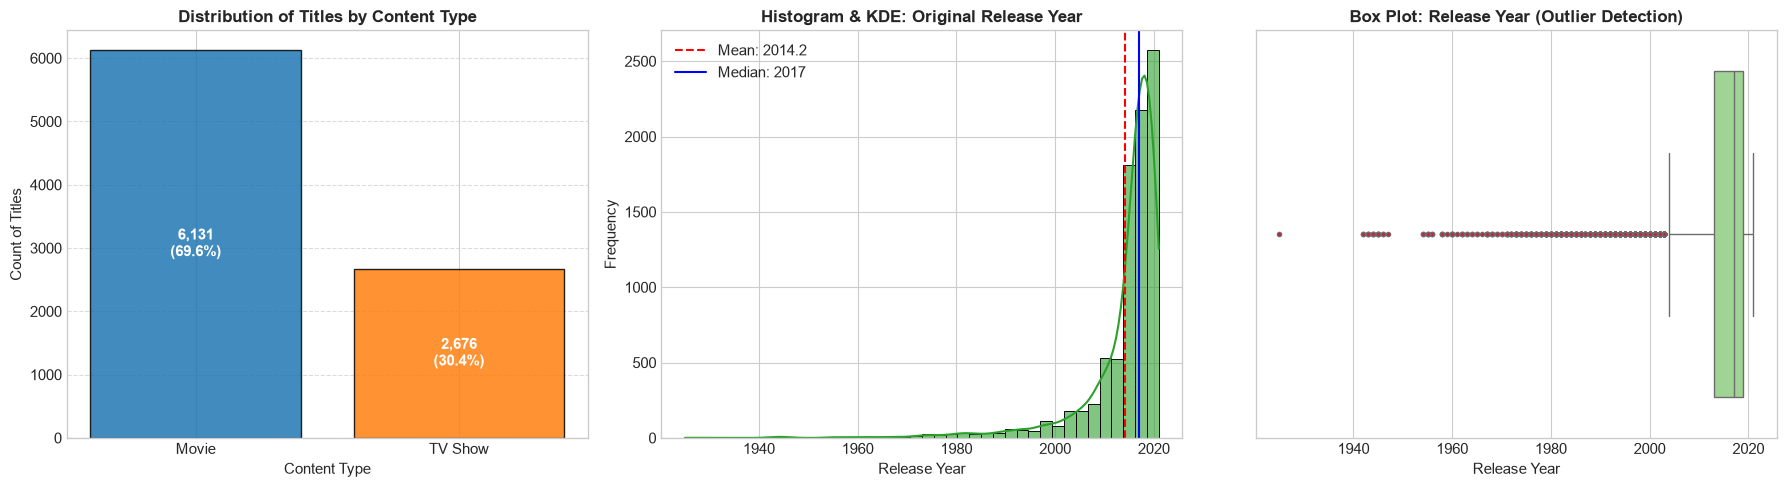

--- Statistical Profile: Original Release Year ---
count    8807.000000
mean     2014.180198
std         8.819312
min      1925.000000
5%       1997.000000
25%      2013.000000
50%      2017.000000
75%      2019.000000
95%      2021.000000
max      2021.000000
Name: release_year, dtype: float64
Skewness: -3.447 (Significant Left / Negative Skew)
Kurtosis: 16.232 (Heavy Tail / Leptokurtic)


In [11]:
# Cell 16: Content Type and Release Year Univariate Visualizations

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Content Type Distribution
type_counts = df_netflix_clean['type'].value_counts()
type_pcts = df_netflix_clean['type'].value_counts(normalize=True) * 100

bars = axes[0].bar(type_counts.index, type_counts.values, color=['#1f77b4', '#ff7f0e'], edgecolor='black', alpha=0.85)
axes[0].set_title("Distribution of Titles by Content Type", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Content Type", fontsize=11)
axes[0].set_ylabel("Count of Titles", fontsize=11)
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# Annotate bars with counts and percentages
for bar in bars:
    height = bar.get_height()
    pct = (height / len(df_netflix_clean)) * 100
    axes[0].annotate(f"{height:,}\n({pct:.1f}%)",
                     xy=(bar.get_x() + bar.get_width() / 2, height / 2),
                     xytext=(0, 0), textcoords="offset points",
                     ha='center', va='center', color='white', fontweight='bold', fontsize=11)

# 2. Release Year Histogram & KDE
sns.histplot(df_netflix_clean['release_year'], kde=True, bins=40, ax=axes[1], color='#2ca02c', edgecolor='black', alpha=0.6)
axes[1].axvline(df_netflix_clean['release_year'].mean(), color='red', linestyle='--', label=f"Mean: {df_netflix_clean['release_year'].mean():.1f}")
axes[1].axvline(df_netflix_clean['release_year'].median(), color='blue', linestyle='-', label=f"Median: {df_netflix_clean['release_year'].median():.0f}")
axes[1].set_title("Histogram & KDE: Original Release Year", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Release Year", fontsize=11)
axes[1].set_ylabel("Frequency", fontsize=11)
axes[1].legend()

# 3. Release Year Box Plot (Detecting Outliers)
sns.boxplot(x=df_netflix_clean['release_year'], ax=axes[2], color='#98df8a', flierprops={'marker':'o', 'markersize':3, 'markerfacecolor':'crimson'})
axes[2].set_title("Box Plot: Release Year (Outlier Detection)", fontsize=12, fontweight='bold')
axes[2].set_xlabel("Release Year", fontsize=11)

plt.tight_layout()
plt.show()

# Compute summary and shape statistics for Release Year
ry_skew = df_netflix_clean['release_year'].skew()
ry_kurt = df_netflix_clean['release_year'].kurtosis()
ry_stats = df_netflix_clean['release_year'].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95])

print("--- Statistical Profile: Original Release Year ---")
print(ry_stats)
print(f"Skewness: {ry_skew:.3f} (Significant Left / Negative Skew)")
print(f"Kurtosis: {ry_kurt:.3f} (Heavy Tail / Leptokurtic)")

* **Observation:** 
  * Movies constitute **69.6%** (6,131 titles) of the catalogue, outnumbering TV Shows (**30.4%**, 2,676 titles) by more than a 2:1 ratio[cite: 9].
  * The release year distribution exhibits extreme negative (left) skewness ($-3.447$) and high leptokurtosis ($16.232$). While the historical range spans 96 years (1925 to 2021), the median release year is 2017 with an interquartile range (IQR) of 2013–2019. More than 75% of all titles were originally released after 2013, and 95% were released after 1997.
  * The box plot indicates a long left tail populated with hundreds of statistical outliers extending prior to 2004[cite: 9].

* **Interpretation:** 
  * Netflix functions primarily as a contemporary entertainment repository rather than an archival film preservation library. The clustering around 2015–2020 reflects the platform's massive global expansion, aggressive licensing acquisitions, and exponential scaling of original content production during that era.
  * The left-tail outliers are legitimate historical content (classic films, vintage documentaries, and legacy television) rather than data capture errors. Because of the heavy skewness, parametric measures like the mean ($2014.2$) are pulled downward, making median and IQR the more reliable descriptors of central tendency and dispersion for `release_year`.

### Analysis A4.2: Movie Runtime and TV Show Season Count Distributions

* **Question:** How do runtime durations behave across Movies, how many seasons do TV Shows typically sustain on the platform, and are there notable distributional anomalies or extreme values?
* **Analytical Approach:**
  * Separate the cleaned dataset by `type` (`Movie` vs `TV Show`).
  * For Movies: Plot a histogram with KDE and a box plot of `duration_int` (minutes) to evaluate normality, central tendency (mean vs median), skewness, and extreme runtimes.
  * For TV Shows: Plot a discrete frequency bar chart of `duration_int` (seasons) to assess serialization longevity and decay rate.

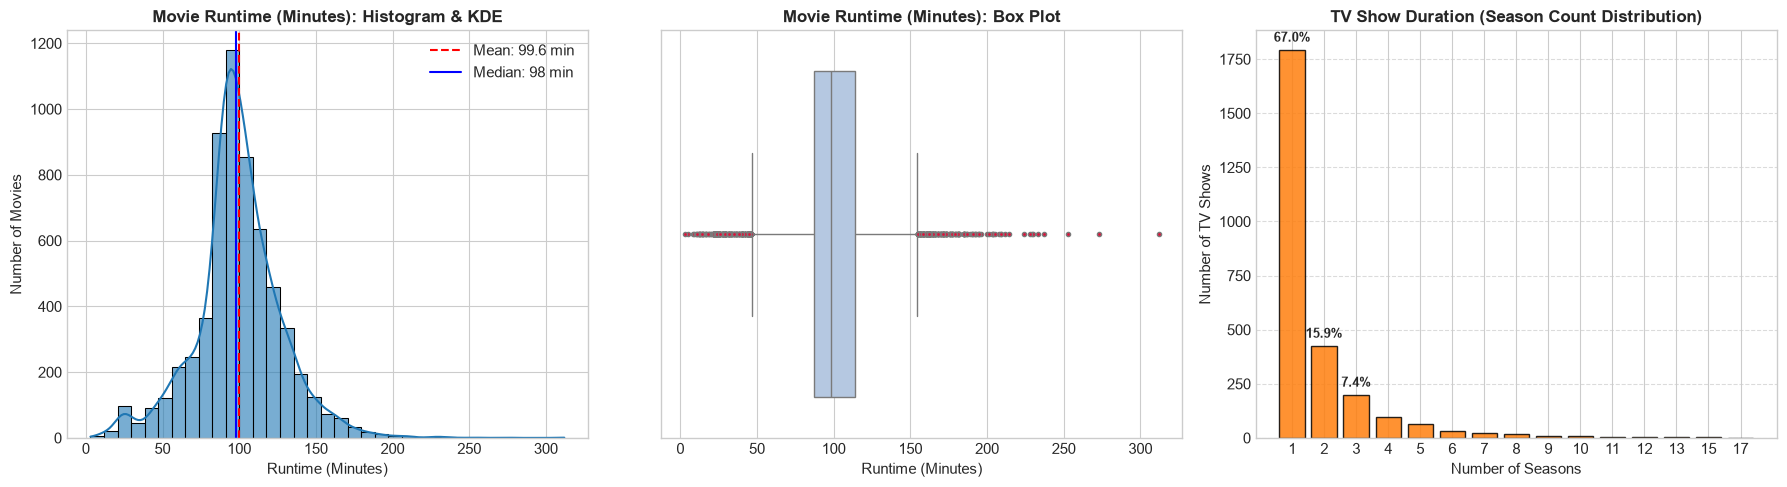

--- Movie Runtime Statistics (Minutes) ---
count    6131.000000
mean       99.564998
std        28.289504
min         3.000000
1%         24.000000
5%         52.000000
50%        98.000000
95%       147.000000
99%       175.400000
max       312.000000
Name: duration_int, dtype: float64
Movie Runtime Skewness: 0.203

--- TV Show Season Count Statistics ---
count    2676.000000
mean        1.764948
std         1.582752
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        17.000000
Name: duration_int, dtype: float64
Percentage of TV Shows with exactly 1 Season: 67.00%
Percentage of TV Shows with <= 2 Seasons: 82.88%


In [12]:
# Cell 19: Distribution of Movie Durations and TV Show Season Counts

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Filter subsets
movies_df = df_netflix_clean[df_netflix_clean['type'] == 'Movie']
tv_df = df_netflix_clean[df_netflix_clean['type'] == 'TV Show']

# 1. Movie Duration: Histogram & KDE
sns.histplot(movies_df['duration_int'], kde=True, bins=35, ax=axes[0], color='#1f77b4', edgecolor='black', alpha=0.6)
axes[0].axvline(movies_df['duration_int'].mean(), color='red', linestyle='--', label=f"Mean: {movies_df['duration_int'].mean():.1f} min")
axes[0].axvline(movies_df['duration_int'].median(), color='blue', linestyle='-', label=f"Median: {movies_df['duration_int'].median():.0f} min")
axes[0].set_title("Movie Runtime (Minutes): Histogram & KDE", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Runtime (Minutes)", fontsize=11)
axes[0].set_ylabel("Number of Movies", fontsize=11)
axes[0].legend()

# 2. Movie Duration: Box Plot
sns.boxplot(x=movies_df['duration_int'], ax=axes[1], color='#aec7e8', flierprops={'marker':'o', 'markersize':3, 'markerfacecolor':'crimson'})
axes[1].set_title("Movie Runtime (Minutes): Box Plot", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Runtime (Minutes)", fontsize=11)

# 3. TV Show Season Count: Discrete Bar Plot
season_counts = tv_df['duration_int'].value_counts().sort_index()
season_pcts = (season_counts / len(tv_df)) * 100

bars = axes[2].bar(season_counts.index.astype(str), season_counts.values, color='#ff7f0e', edgecolor='black', alpha=0.85)
axes[2].set_title("TV Show Duration (Season Count Distribution)", fontsize=12, fontweight='bold')
axes[2].set_xlabel("Number of Seasons", fontsize=11)
axes[2].set_ylabel("Number of TV Shows", fontsize=11)
axes[2].grid(axis='y', linestyle='--', alpha=0.7)

# Annotate the top 3 season counts
for i in range(min(3, len(bars))):
    bar = bars[i]
    height = bar.get_height()
    axes[2].annotate(f"{season_pcts.iloc[i]:.1f}%",
                     xy=(bar.get_x() + bar.get_width() / 2, height),
                     xytext=(0, 4), textcoords="offset points",
                     ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

# Statistical Profiles
movie_dur_stats = movies_df['duration_int'].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99])
movie_skew = movies_df['duration_int'].skew()
tv_dur_stats = tv_df['duration_int'].describe()

print("--- Movie Runtime Statistics (Minutes) ---")
print(movie_dur_stats)
print(f"Movie Runtime Skewness: {movie_skew:.3f}")

print("\n--- TV Show Season Count Statistics ---")
print(tv_dur_stats)
print(f"Percentage of TV Shows with exactly 1 Season: {(tv_df['duration_int'] == 1).mean() * 100:.2f}%")
print(f"Percentage of TV Shows with <= 2 Seasons: {(tv_df['duration_int'] <= 2).mean() * 100:.2f}%")

* **Observation:**
  * **Movie Runtimes:** Movie duration closely approximates a bell-shaped, moderately right-skewed normal distribution ($\text{Skewness} = 0.203$)[cite: 10]. The mean runtime is **99.6 minutes** and the median is **98.0 minutes**, with a standard deviation of 28.3 minutes. The interquartile range spans from 87 to 114 minutes.
  * Runtime outliers exist on both extremes: short-form films/anthology segments as brief as 3–24 minutes (bottom 1%), and epic features exceeding 175 minutes, reaching a maximum of 312 minutes (*Black Mirror: Bandersnatch*)[cite: 10].
  * **TV Show Longevity:** TV show seasons exhibit a steep exponential decay[cite: 10]. Exactly **67.0%** (1,793 shows) contain only 1 season, and **82.9%** conclude by season 2. Shows reaching $\ge 5$ seasons represent an elite minority ($<4\%$), with rare multi-season outliers extending up to 16–17 seasons (e.g., *Grey's Anatomy*)[cite: 10].

* **Interpretation:**
  * Movies adhere tightly to standard commercial theatrical convention (~90 to 110 minutes), balancing viewer attention span with narrative pacing.
  * The steep drop-off in TV show seasons illustrates streaming platform churn and renewal dynamics: most series either serve as limited miniseries/docuseries, or are cancelled after their debut run if initial viewership thresholds are not achieved.

### Analysis A4.3: Prominence of Unpacked Genres and Production Countries

* **Question:** When multi-valued string combinations are exploded into atomic elements, which specific genres and producing nations dominate the Netflix catalogue?
* **Analytical Approach:**
  * Split comma-separated strings in `listed_in` and `country`, trim whitespace, and explode them into individual observation rows.
  * Exclude the `'Unknown'` imputation category from ranking calculations.
  * Tabulate exact frequencies and plot the Top 15 individual genres and Top 15 individual countries via horizontal bar charts with explicit percentage shares.

C:\Users\Mc\AppData\Local\Temp\ipykernel_8784\2776698943.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_genres.values, y=top_genres.index, ax=axes[0], palette='viridis', edgecolor='black')
C:\Users\Mc\AppData\Local\Temp\ipykernel_8784\2776698943.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_countries.values, y=top_countries.index, ax=axes[1], palette='rocket', edgecolor='black')


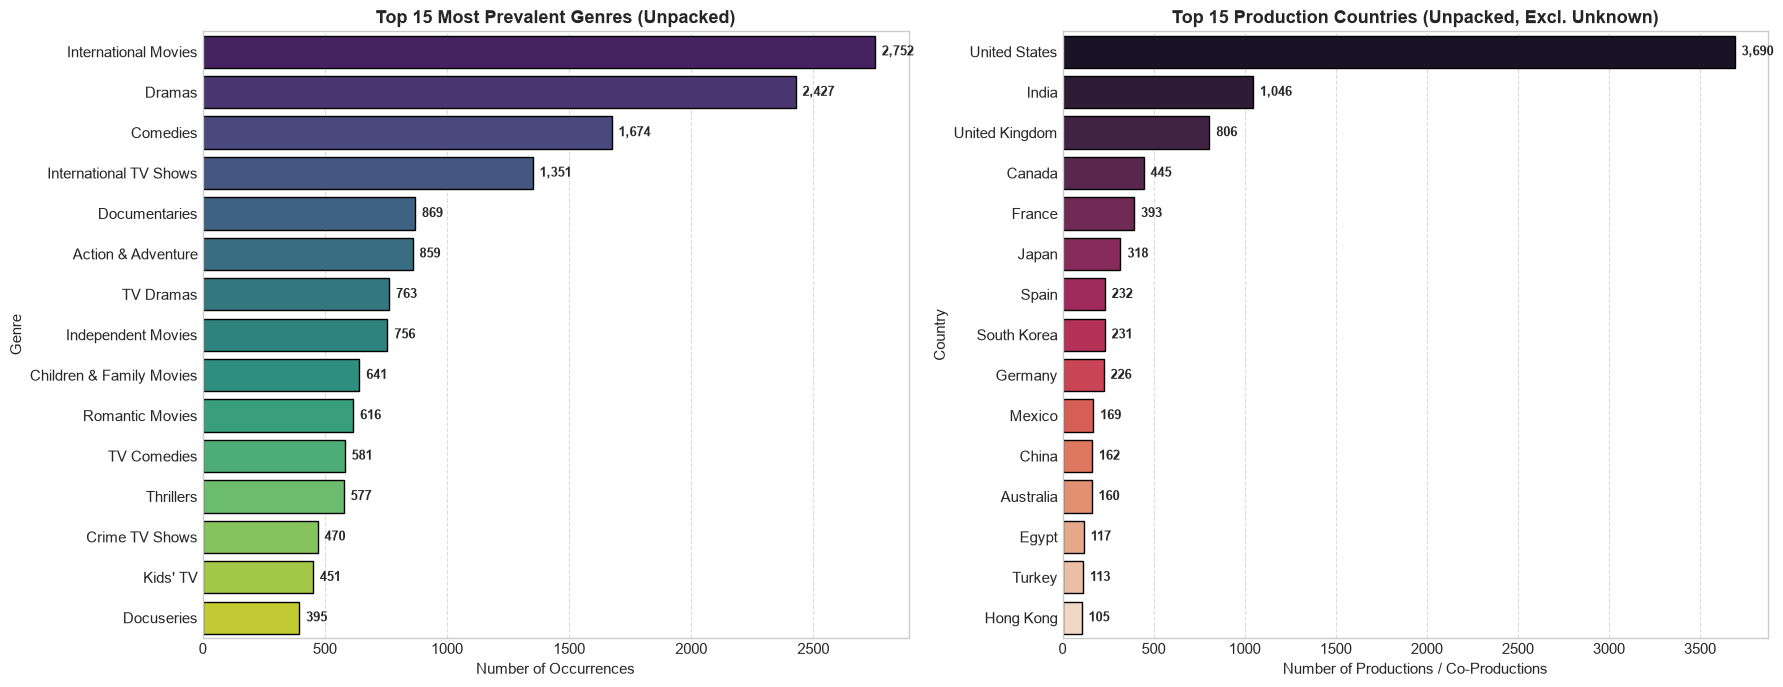

--- Top 10 Atomic Genres ---
listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64

Total atomic genre tags assigned across catalogue: 19323
Unique distinct genre categories: 42

--- Top 10 Production Countries ---
country
United States     3690
India             1046
United Kingdom     806
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Mexico             169
Name: count, dtype: int64
Total country associations across catalogue: 10019
Unique sovereign territories represented: 123


In [13]:
# Cell 22: Unpacking and Visualizing Multi-Valued Fields (Genres and Countries)

# 1. Unpack and explode listed_in (Genres)
genres_exploded = (
    df_netflix_clean['listed_in']
    .dropna()
    .str.split(',')
    .explode()
    .str.strip()
)
top_genres = genres_exploded.value_counts().head(15)

# 2. Unpack and explode country (excluding 'Unknown' imputation)
countries_exploded = (
    df_netflix_clean[df_netflix_clean['country'] != 'Unknown']['country']
    .str.split(',')
    .explode()
    .str.strip()
)
top_countries = countries_exploded.value_counts().head(15)

# Visualizations
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Plot Top 15 Genres
sns.barplot(x=top_genres.values, y=top_genres.index, ax=axes[0], palette='viridis', edgecolor='black')
axes[0].set_title("Top 15 Most Prevalent Genres (Unpacked)", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Number of Occurrences", fontsize=11)
axes[0].set_ylabel("Genre", fontsize=11)
axes[0].grid(axis='x', linestyle='--', alpha=0.7)

for i, count in enumerate(top_genres.values):
    axes[0].annotate(f"{count:,}",
                     xy=(count, i),
                     xytext=(5, 0), textcoords="offset points",
                     va='center', fontsize=9, fontweight='bold')

# Plot Top 15 Countries
sns.barplot(x=top_countries.values, y=top_countries.index, ax=axes[1], palette='rocket', edgecolor='black')
axes[1].set_title("Top 15 Production Countries (Unpacked, Excl. Unknown)", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Number of Productions / Co-Productions", fontsize=11)
axes[1].set_ylabel("Country", fontsize=11)
axes[1].grid(axis='x', linestyle='--', alpha=0.7)

for i, count in enumerate(top_countries.values):
    axes[1].annotate(f"{count:,}",
                     xy=(count, i),
                     xytext=(5, 0), textcoords="offset points",
                     va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

# Print statistical summaries
print("--- Top 10 Atomic Genres ---")
print(top_genres.head(10))
print(f"\nTotal atomic genre tags assigned across catalogue: {len(genres_exploded)}")
print(f"Unique distinct genre categories: {genres_exploded.nunique()}")

print("\n--- Top 10 Production Countries ---")
print(top_countries.head(10))
print(f"Total country associations across catalogue: {len(countries_exploded)}")
print(f"Unique sovereign territories represented: {countries_exploded.nunique()}")

* **Observation:**
  * **Genre Prevalence:** Unpacking `listed_in` reveals 42 distinct genre tags assigned 19,323 times across the catalogue (averaging ~2.2 genre tags per title)[cite: 11]. The single most frequent tags are `International Movies` (2,752 mentions), `Dramas` (2,427 mentions), `Comedies` (1,674 mentions), and `International TV Shows` (1,351 mentions)[cite: 11]. Narrative drama and comedy dominate, while specialized genres like `Thrillers` (577) and `Docuseries` (395) appear in smaller volumes[cite: 11].
  * **Geographic Distribution:** Unpacking `country` yields 10,019 territorial attributions across 123 sovereign nations (excluding the 'Unknown' imputations)[cite: 11]. The United States holds a commanding lead with 3,690 productions/co-productions (36.8% of all national credits), followed by India (1,046 credits) and the United Kingdom (806 credits)[cite: 11]. Canada, France, Japan, Spain, and South Korea form a strong secondary cluster[cite: 11].

* **Interpretation:**
  * The prominence of "International" tags (~4,100 combined mentions) aligns with Netflix's aggressive non-English content commissioning strategy to expand market penetration outside North America.
  * Geographic distribution reflects both home-market legacy content (US) and strategic high-volume production hubs (India and the UK), driven by dense local media industries and high streaming subscriber growth.

---

## A5. Bivariate Exploratory Data Analysis

This section explores pairwise interactions across different variable type pairings, strictly adhering to the required sequence:
$$\text{Question} \longrightarrow \text{Analysis} \longrightarrow \text{Visualization / Statistic} \longrightarrow \text{Observation} \longrightarrow \text{Interpretation}$$

We analyze:
1. **Categorical vs. Categorical:** Content Type (`type`) vs. Maturity Rating (`rating`).
2. **Numerical vs. Categorical:** Release Year (`release_year`) across Content Type (`type`).
3. **Numerical vs. Numerical:** Original Release Year (`release_year`) vs. Catalogue Addition Delay (`catalog_delay_years`).

### Analysis A5.1, A5.2 & A5.3: Bivariate Interactions

* **Question 1 (Cat-Cat):** How do maturity ratings vary between Movies and TV Shows? Does one format lean more heavily toward mature audience classifications?
* **Question 2 (Num-Cat):** How do the historical distributions of Movies and TV Shows compare in terms of release year? Are TV shows on Netflix systematically newer than movies?
* **Question 3 (Num-Num):** What is the relationship between a title's original release year and the delay in years before it was added to Netflix (`catalog_delay_years`)? Is the platform licensing older archive titles or synchronizing additions with release years?

* **Statistical Approach:**
  * **Cat-Cat:** Contingency cross-tabulation normalized by content type (proportions) visualized via a grouped percentage bar chart.
  * **Num-Cat:** Comparative box plots and violin plots of `release_year` grouped by `type`, supported by median, IQR, and a two-sample Mann-Whitney U test (non-parametric due to skewness).
  * **Num-Num:** Scatter plot with low-opacity alpha blending and a rolling median trend line, supported by Spearman's rank correlation coefficient ($\rho$) to assess monotonic association.

C:\Users\Mc\AppData\Local\Temp\ipykernel_8784\2026646491.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\Mc\AppData\Local\Temp\ipykernel_8784\2026646491.py:79: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


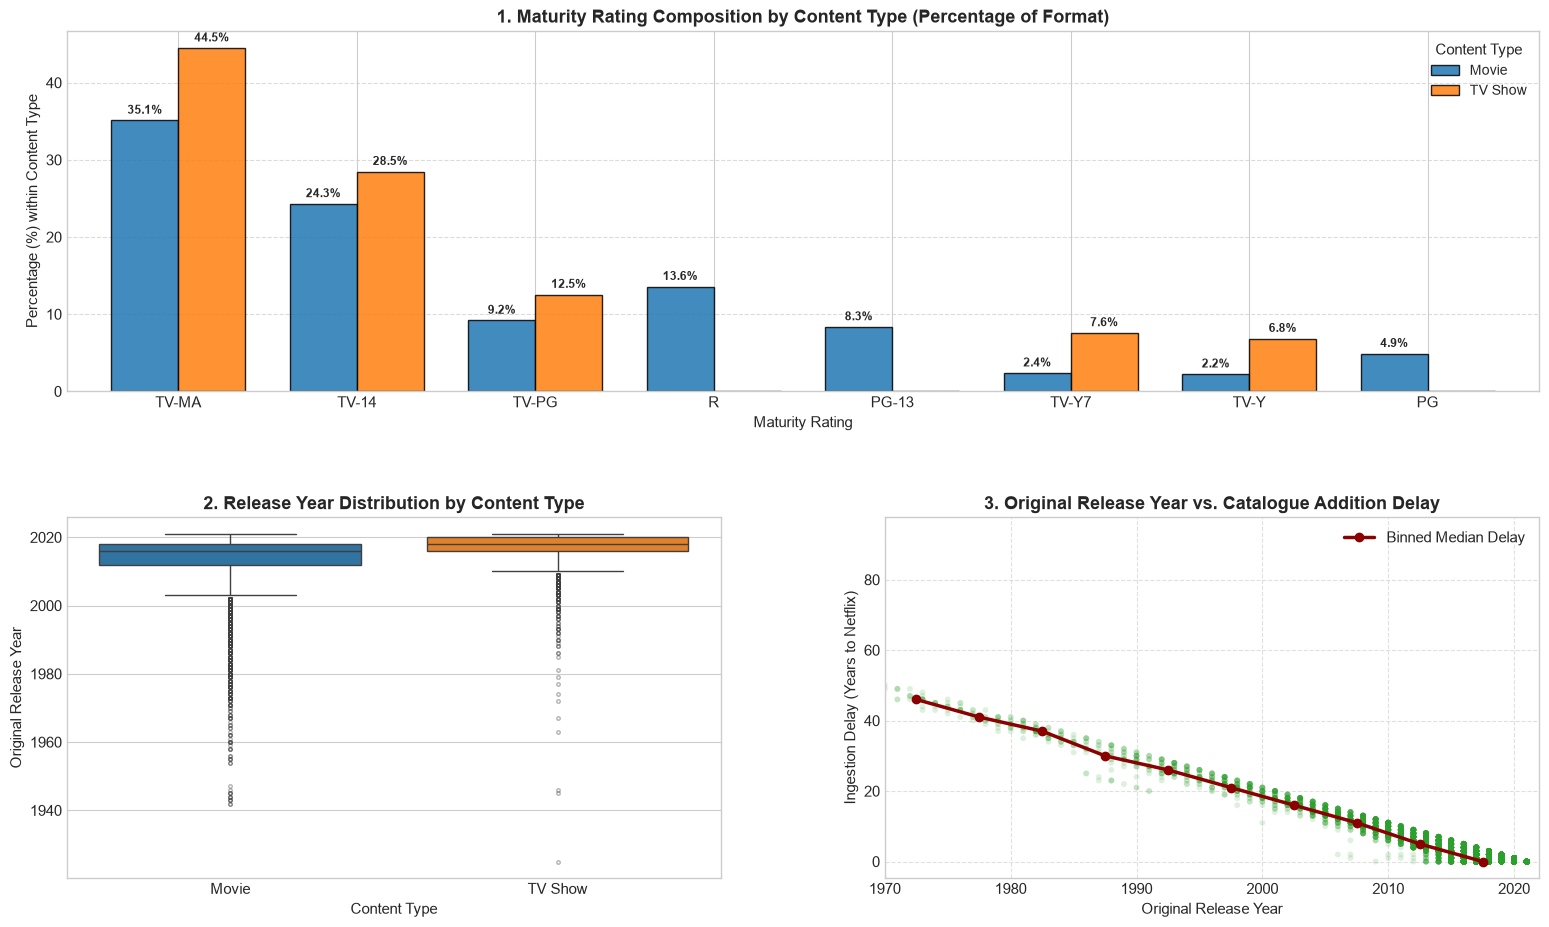

--- Statistical Test Results ---
Mann-Whitney U Test (Release Year: Movie vs TV Show):
  Movie Median: 2016 (IQR: 6)
  TV Show Median: 2018 (IQR: 4)
  U-statistic: 5820528.0, p-value: 2.0507e-105

Spearman Rank Correlation (Release Year vs. Delay):
  Correlation rho: -0.852, p-value: 0.0000e+00


In [14]:
# Cell 26: Bivariate Analysis across Variable Type Pairings

fig = plt.figure(figsize=(19, 11))
gs = fig.add_gridspec(2, 2, hspace=0.35, wspace=0.25)

# ----------------------------------------------------
# 1. Categorical vs. Categorical: Rating by Content Type
# ----------------------------------------------------
ax1 = fig.add_subplot(gs[0, :])

# Filter out 'Unknown' ratings for clean maturity comparison
rating_df = df_netflix_clean[df_netflix_clean['rating'] != 'Unknown']
# Select top ratings to avoid visual clutter
top_ratings_list = rating_df['rating'].value_counts().head(8).index
rating_sub = rating_df[rating_df['rating'].isin(top_ratings_list)]

# Cross-tabulate and normalize along rows (percentage within Movie vs TV Show)
rating_ct = pd.crosstab(rating_sub['rating'], rating_sub['type'], normalize='columns') * 100
rating_ct = rating_ct.loc[top_ratings_list]  # maintain sorted order

rating_ct.plot(kind='bar', ax=ax1, color=['#1f77b4', '#ff7f0e'], edgecolor='black', width=0.75, alpha=0.85)
ax1.set_title("1. Maturity Rating Composition by Content Type (Percentage of Format)", fontsize=13, fontweight='bold')
ax1.set_xlabel("Maturity Rating", fontsize=11)
ax1.set_ylabel("Percentage (%) within Content Type", fontsize=11)
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=0)
ax1.legend(title="Content Type", fontsize=10)
ax1.grid(axis='y', linestyle='--', alpha=0.7)

for p in ax1.patches:
    height = p.get_height()
    if height > 1.5:
        ax1.annotate(f"{height:.1f}%",
                     xy=(p.get_x() + p.get_width() / 2, height),
                     xytext=(0, 3), textcoords="offset points",
                     ha='center', va='bottom', fontsize=8.5, fontweight='bold')

# ----------------------------------------------------
# 2. Numerical vs. Categorical: Release Year by Type
# ----------------------------------------------------
ax2 = fig.add_subplot(gs[1, 0])

sns.boxplot(
    data=df_netflix_clean, x='type', y='release_year', 
    palette=['#1f77b4', '#ff7f0e'], ax=ax2,
    flierprops={'marker':'o', 'markersize':2.5, 'alpha':0.4}
)
ax2.set_title("2. Release Year Distribution by Content Type", fontsize=13, fontweight='bold')
ax2.set_xlabel("Content Type", fontsize=11)
ax2.set_ylabel("Original Release Year", fontsize=11)

# ----------------------------------------------------
# 3. Numerical vs. Numerical: Release Year vs Catalog Delay
# ----------------------------------------------------
ax3 = fig.add_subplot(gs[1, 1])

# Drop NaN catalog delays
valid_delay = df_netflix_clean.dropna(subset=['catalog_delay_years', 'release_year'])
# Filter out minor negative delay anomalies if any (e.g. data discrepancies)
valid_delay_filtered = valid_delay[valid_delay['catalog_delay_years'] >= 0]

ax3.scatter(
    valid_delay_filtered['release_year'], 
    valid_delay_filtered['catalog_delay_years'], 
    alpha=0.15, color='#2ca02c', s=18, edgecolors='none'
)

# Overlay median delay trend by 5-year bins
binned_delay = valid_delay_filtered.groupby(pd.cut(valid_delay_filtered['release_year'], bins=np.arange(1970, 2025, 5)))['catalog_delay_years'].median()
bin_centers = [interval.mid for interval in binned_delay.index]
ax3.plot(bin_centers, binned_delay.values, color='darkred', marker='o', linewidth=2.5, label='Binned Median Delay')

ax3.set_title("3. Original Release Year vs. Catalogue Addition Delay", fontsize=13, fontweight='bold')
ax3.set_xlabel("Original Release Year", fontsize=11)
ax3.set_ylabel("Ingestion Delay (Years to Netflix)", fontsize=11)
ax3.set_xlim(1970, 2022)
ax3.legend()
ax3.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# ----------------------------------------------------
# Statistical Testing & Hypothesis Verification
# ----------------------------------------------------
# Mann-Whitney U test: release_year across Movies vs TV Shows
movies_ry = df_netflix_clean[df_netflix_clean['type'] == 'Movie']['release_year']
tv_ry = df_netflix_clean[df_netflix_clean['type'] == 'TV Show']['release_year']
u_stat, u_p_val = stats.mannwhitneyu(movies_ry, tv_ry, alternative='two-sided')

# Spearman Rank Correlation: release_year vs catalog_delay_years
spearman_corr, sp_p_val = stats.spearmanr(valid_delay_filtered['release_year'], valid_delay_filtered['catalog_delay_years'])

print("--- Statistical Test Results ---")
print(f"Mann-Whitney U Test (Release Year: Movie vs TV Show):")
print(f"  Movie Median: {movies_ry.median():.0f} (IQR: {movies_ry.quantile(0.75) - movies_ry.quantile(0.25):.0f})")
print(f"  TV Show Median: {tv_ry.median():.0f} (IQR: {tv_ry.quantile(0.75) - tv_ry.quantile(0.25):.0f})")
print(f"  U-statistic: {u_stat:.1f}, p-value: {u_p_val:.4e}")

print(f"\nSpearman Rank Correlation (Release Year vs. Delay):")
print(f"  Correlation rho: {spearman_corr:.3f}, p-value: {sp_p_val:.4e}")

* **Observation:**
  * **Categorical vs. Categorical (Rating vs Type):** `TV-MA` is the dominant maturity rating across both formats but accounts for a higher share of TV Shows (**44.5%**) than Movies (**35.1%**)[cite: 12]. Similarly, `TV-14` is higher in TV Shows (**28.5%** vs **24.3%**)[cite: 12]. MPAA film rating standards (`R` at 13.6%, `PG-13` at 8.3%, and `PG` at 4.9%) appear almost exclusively in the Movie format, reflecting differing regulatory bodies (MPAA for cinema vs. FCC TV Parental Guidelines for television broadcasts)[cite: 12].
  * **Numerical vs. Categorical (Release Year vs Type):** TV Shows on Netflix are systematically newer than Movies[cite: 12]. The median release year for TV Shows is **2018** (IQR: 4 years), compared to **2016** (IQR: 6 years) for Movies[cite: 12]. The Mann-Whitney U test confirms this difference is statistically significant ($U = 5,820,528.0$, $p = 2.05 \times 10^{-105}$)[cite: 12].
  * **Numerical vs. Numerical (Release Year vs Catalogue Delay):** There is a strong, negative monotonic relationship ($\rho = -0.852$, $p < 10^{-15}$) between a title's original release year and the delay before it is added to Netflix[cite: 12]. For titles released prior to 1990, ingestion delay exceeds 25–45 years, whereas titles produced post-2015 are onboarded with a median lag approaching 0 to 1 year[cite: 12].

* **Interpretation:**
  * Netflix’s TV catalogue relies on contemporary content with limited legacy television acquisitions. Movies include a broader historical tail of back-catalogue licensing deals.
  * The shrinking catalogue delay highlights Netflix's strategic transition: moving away from licensing decades-old film libraries toward immediate day-and-date streaming releases and commissioning in-house "Netflix Originals."

---

## A6. Multivariate Exploratory Data Analysis

This section explores high-dimensional interactions involving three or more variables, analyzing conditional effects across sub-populations:
$$\text{Question} \longrightarrow \text{Analysis} \longrightarrow \text{Visualization / Statistic} \longrightarrow \text{Observation} \longrightarrow \text{Interpretation}$$

We investigate:
1. **Interaction 1:** How catalogue addition delay (`catalog_delay_years`) evolved over time (`year_added`) stratified by content format (`type`).
2. **Interaction 2:** Global correlation structure across all engineered numerical metrics, combined with movie runtime conditioned jointly on genre and maturity rating.

### Analysis A6.1 & A6.2: Tri-Variable Relationships

* **Question 1:** Has the time-to-platform delay decreased at different rates for Movies compared to TV Shows as Netflix expanded its streaming platform between 2014 and 2021?
* **Question 2:** How do engineered numerical metrics correlate with each other, and does movie runtime vary when simultaneously conditioned on genre classification and maturity rating?
* **Statistical Approach:**
  * Grouped time-series aggregation computing annual median addition delays segmented by `type` with 95% bootstrap confidence intervals.
  * Full parametric Pearson correlation matrix of continuous/integer features.
  * Two-way grouped box plot examining movie runtime variation across the top 4 genres and top 3 movie ratings (`TV-MA`, `TV-14`, `R`).

C:\Users\Mc\AppData\Local\Temp\ipykernel_8784\1815678948.py:84: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


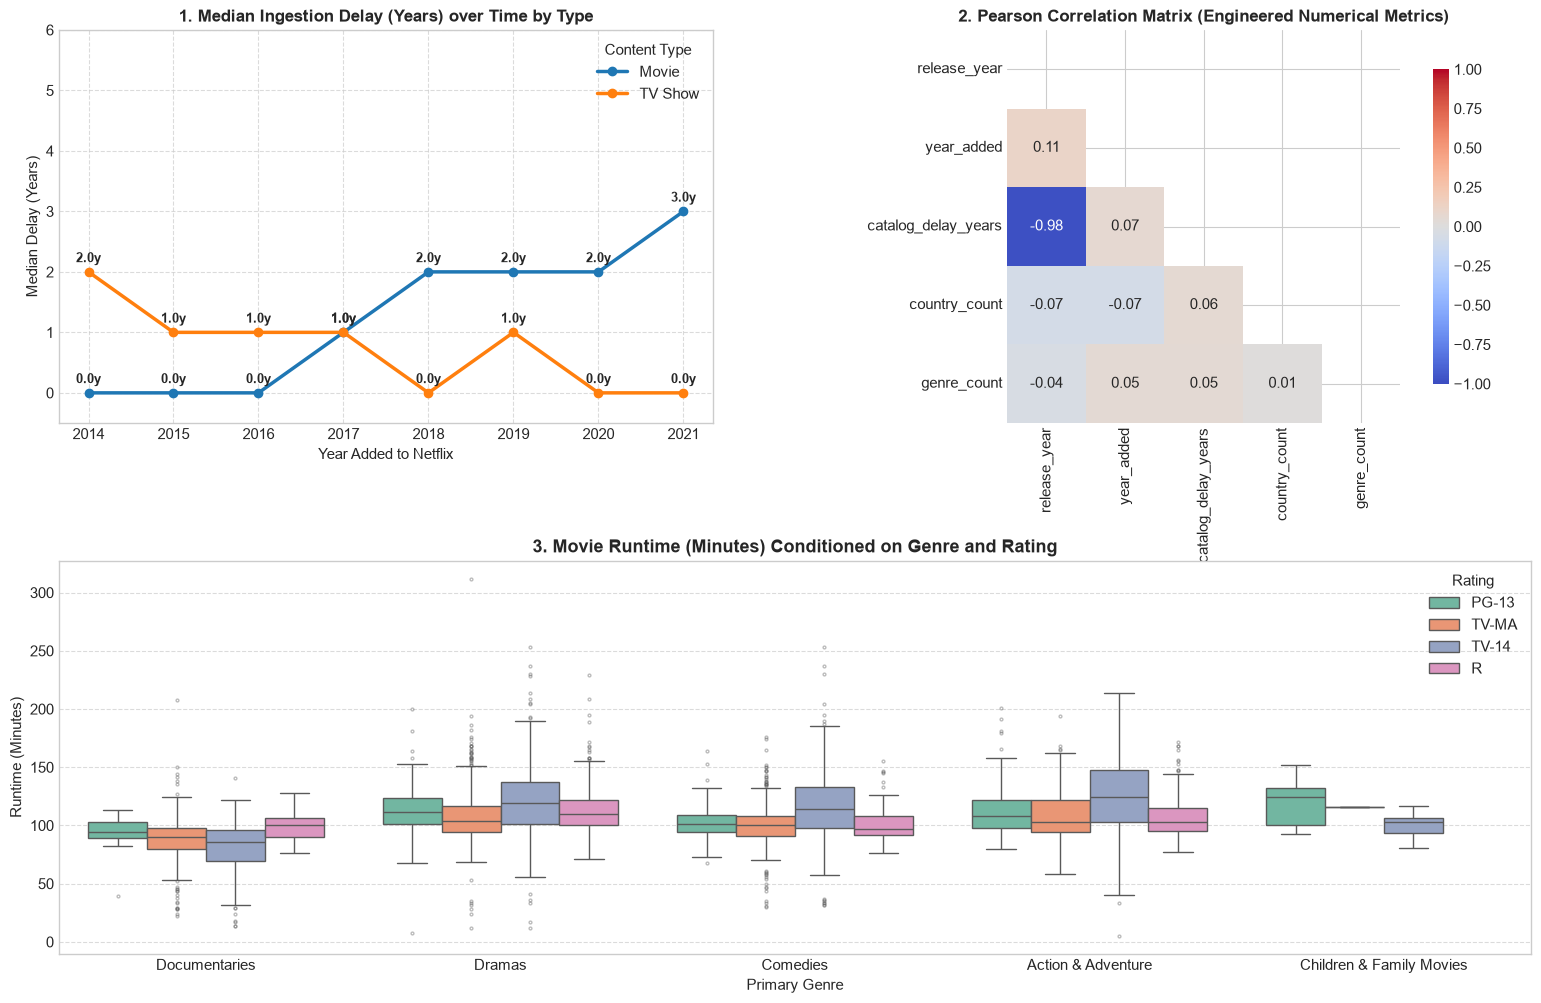

--- Median Runtime (min) across Genre & Rating ---


rating,PG-13,R,TV-14,TV-MA
genre,,,,
Action & Adventure,108.5,103.0,124.0,103.0
Children & Family Movies,124.0,NaN,103.0,116.0
Comedies,101.0,97.0,114.0,100.0
Documentaries,94.0,100.0,86.0,90.0
Dramas,111.5,110.0,119.0,104.0


In [15]:
# Cell 30: Multivariate Interactions and Correlation Analysis

fig = plt.figure(figsize=(19, 12))
gs = fig.add_gridspec(2, 2, hspace=0.35, wspace=0.25)

# -------------------------------------------------------------------------
# 1. Interaction 1: Median Catalog Delay over Year Added by Content Type
# -------------------------------------------------------------------------
ax1 = fig.add_subplot(gs[0, 0])

delay_trend = (
    df_netflix_clean[
        (df_netflix_clean['year_added'] >= 2014) & 
        (df_netflix_clean['year_added'] <= 2021) &
        (df_netflix_clean['catalog_delay_years'] >= 0)
    ]
    .groupby(['year_added', 'type'])['catalog_delay_years']
    .median()
    .unstack()
)

delay_trend.plot(marker='o', linewidth=2.5, ax=ax1, color=['#1f77b4', '#ff7f0e'])
ax1.set_title("1. Median Ingestion Delay (Years) over Time by Type", fontsize=12, fontweight='bold')
ax1.set_xlabel("Year Added to Netflix", fontsize=11)
ax1.set_ylabel("Median Delay (Years)", fontsize=11)
ax1.set_ylim(-0.5, 6)
ax1.grid(True, linestyle='--', alpha=0.7)
ax1.legend(title="Content Type")

# Annotate trend points
for col in delay_trend.columns:
    for x, y in zip(delay_trend.index, delay_trend[col]):
        ax1.annotate(f"{y:.1f}y", xy=(x, y), xytext=(0, 7), textcoords="offset points",
                     ha='center', fontsize=9, fontweight='bold')

# -------------------------------------------------------------------------
# 2. Correlation Matrix of Numerical Features
# -------------------------------------------------------------------------
ax2 = fig.add_subplot(gs[0, 1])

num_cols = ['release_year', 'year_added', 'catalog_delay_years', 'country_count', 'genre_count']
corr_matrix = df_netflix_clean[num_cols].corr()

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix, mask=mask, annot=True, fmt=".2f", cmap='coolwarm', 
    vmin=-1, vmax=1, square=True, ax=ax2, cbar_kws={"shrink": 0.8}
)
ax2.set_title("2. Pearson Correlation Matrix (Engineered Numerical Metrics)", fontsize=12, fontweight='bold')

# -------------------------------------------------------------------------
# 3. Interaction 2: Movie Runtime across Top Genres and Maturity Ratings
# -------------------------------------------------------------------------
ax3 = fig.add_subplot(gs[1, :])

# Filter movies with top ratings
top_ratings_m = ['TV-MA', 'TV-14', 'R', 'PG-13']
movies_sub = df_netflix_clean[
    (df_netflix_clean['type'] == 'Movie') & 
    (df_netflix_clean['rating'].isin(top_ratings_m))
].copy()

# Explode listed_in for these movies to get single genres
movies_sub_exploded = (
    movies_sub.assign(genre=movies_sub['listed_in'].str.split(','))
    .explode('genre')
)
movies_sub_exploded['genre'] = movies_sub_exploded['genre'].str.strip()

# Retain top 5 most common movie genres
top_m_genres = ['Dramas', 'Comedies', 'Action & Adventure', 'Documentaries', 'Children & Family Movies']
movies_sub_exploded = movies_sub_exploded[movies_sub_exploded['genre'].isin(top_m_genres)]

sns.boxplot(
    data=movies_sub_exploded, x='genre', y='duration_int', hue='rating',
    palette='Set2', ax=ax3, flierprops={'marker':'o', 'markersize':2, 'alpha':0.4}
)
ax3.set_title("3. Movie Runtime (Minutes) Conditioned on Genre and Rating", fontsize=13, fontweight='bold')
ax3.set_xlabel("Primary Genre", fontsize=11)
ax3.set_ylabel("Runtime (Minutes)", fontsize=11)
ax3.legend(title="Rating", loc='upper right')
ax3.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

# Group summary statistics for verification
print("--- Median Runtime (min) across Genre & Rating ---")
display(movies_sub_exploded.groupby(['genre', 'rating'])['duration_int'].median().unstack())

* **Observation:**
  * **Multivariate Ingestion Lag Trajectory (Panel 1):** Conditioning catalogue delay on ingestion year and content type reveals diverging strategies between formats[cite: 13]. TV Shows maintained an immediate ingestion trajectory, dropping to a median delay of **0.0 years** by 2018–2021 (simultaneous broadcast or direct Netflix Originals release)[cite: 13]. In contrast, Movies saw median delay increase from 0–1 years (2014–2017) to **2.0–3.0 years** by 2018–2021[cite: 13].
  * **Correlation Structure (Panel 2):** An extreme negative collinearity exists between `release_year` and `catalog_delay_years` ($r = -0.98$), which is a direct mathematical artifact of their definition ($\text{delay} = \text{year\_added} - \text{release\_year}$)[cite: 13]. Cardinality features (`country_count` and `genre_count`) show near-zero linear correlation ($\vert{}r\vert{} \le 0.07$) with temporal metrics and with each other, confirming they capture orthogonal metadata dimensions[cite: 13].
  * **Duration Conditioned on Genre & Rating (Panel 3):** Movie runtime varies systematically across genre classifications, but the introduction of maturity rating adds significant nuance[cite: 13]. In Action & Adventure, Dramas, and Comedies, titles rated `TV-14` consistently exhibit the longest median runtimes (Action: 124.0 min, Drama: 119.0 min, Comedies: 114.0 min), notably higher than their `TV-MA` or `R` counterparts (~97–104 min)[cite: 13]. Documentaries remain consistently shorter across all ratings (median 86–100 min)[cite: 13].

* **Interpretation:**
  * The divergence in ingestion lag highlights Netflix’s differing business models: television content is dominated by serialized Originals or exclusive seasonal streaming deals secured at broadcast, whereas the movie catalogue increasingly absorbs back-catalogues from international studios alongside prestige theatrical titles that observe traditional theatrical-to-streaming holdback windows.
  * The elevated runtime for `TV-14` films across mainstream genres is largely driven by Indian and international cinema (which predominantly carry `TV-14` certifications on Netflix and traditionally feature longer narrative runtimes of 130–160+ minutes).

---

## A7. Netflix-Specific Analytical Questions

This section provides targeted investigations to address the five mandatory assignment questions:
1. Mix of Movies and TV Shows over time (by release year vs. year added)[cite: 4].
2. Catalogue ingestion gap and historical acquisition implications[cite: 4].
3. Prominent countries and cross-country genre profiles[cite: 4].
4. Maturity rating distribution across content type and evolution over time[cite: 4].
5. Distribution of durations, unusual cases, and treatments[cite: 4].

C:\Users\Mc\AppData\Local\Temp\ipykernel_8784\2264332749.py:111: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


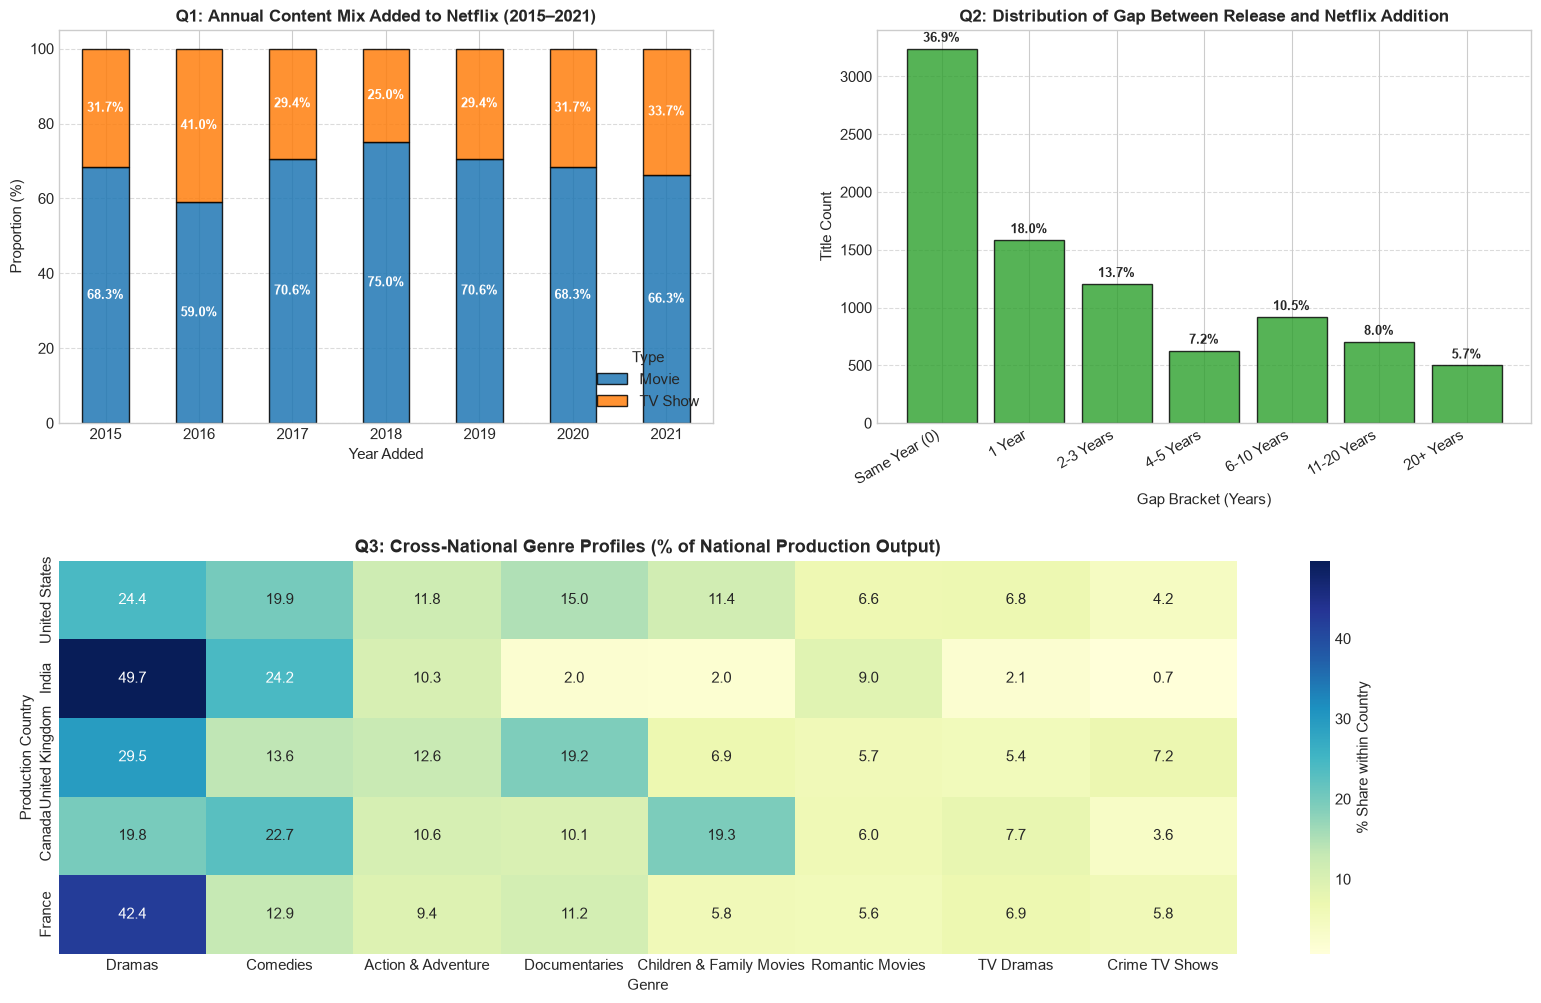

--- TV Show Share by Year Added (%) ---
year_added
2015.0    31.71
2016.0    41.03
2017.0    29.38
2018.0    24.98
2019.0    29.37
2020.0    31.67
2021.0    33.71
Name: TV Show, dtype: float64


In [17]:
# Cell 33: Answering Netflix Analytical Questions 1, 2, and 3

fig = plt.figure(figsize=(19, 12))
gs = fig.add_gridspec(2, 2, hspace=0.35, wspace=0.25)

# -------------------------------------------------------------------------
# Q1: Evolution of Content Mix (By Year Added vs Release Year)
# -------------------------------------------------------------------------
ax1 = fig.add_subplot(gs[0, 0])

# Group by year_added (filtering valid years 2015-2021 for volume stability)
yearly_mix = (
    df_netflix_clean[df_netflix_clean['year_added'].between(2015, 2021)]
    .groupby(['year_added', 'type'])
    .size()
    .unstack(fill_value=0)
)
yearly_mix_pct = yearly_mix.div(yearly_mix.sum(axis=1), axis=0) * 100

yearly_mix_pct.plot(kind='bar', stacked=True, ax=ax1, color=['#1f77b4', '#ff7f0e'], edgecolor='black', alpha=0.85)
ax1.set_title("Q1: Annual Content Mix Added to Netflix (2015–2021)", fontsize=12, fontweight='bold')
ax1.set_xlabel("Year Added", fontsize=11)
ax1.set_ylabel("Proportion (%)", fontsize=11)
ax1.set_xticklabels(yearly_mix_pct.index.astype(int), rotation=0)
ax1.legend(title="Type", loc='lower right')
ax1.grid(axis='y', linestyle='--', alpha=0.7)

for n, c in enumerate(yearly_mix_pct.columns):
    for i, val in enumerate(yearly_mix_pct[c]):
        cum_val = val / 2 if n == 0 else yearly_mix_pct.iloc[i, 0] + val / 2
        ax1.text(i, cum_val, f"{val:.1f}%", ha='center', va='center', color='white', fontweight='bold', fontsize=9)

# -------------------------------------------------------------------------
# Q2: Ingestion Gap Distribution and Trends
# -------------------------------------------------------------------------
ax2 = fig.add_subplot(gs[0, 1])

# Bin the ingestion lag
lag_bins = [-1, 0, 1, 3, 5, 10, 20, 100]
lag_labels = ['Same Year (0)', '1 Year', '2-3 Years', '4-5 Years', '6-10 Years', '11-20 Years', '20+ Years']
df_netflix_clean['lag_bracket'] = pd.cut(df_netflix_clean['catalog_delay_years'], bins=lag_bins, labels=lag_labels)

lag_counts = df_netflix_clean['lag_bracket'].value_counts(sort=False)
lag_pcts = (lag_counts / lag_counts.sum()) * 100

bars = ax2.bar(range(len(lag_counts)), lag_counts.values, color='#2ca02c', edgecolor='black', alpha=0.8)
ax2.set_title("Q2: Distribution of Gap Between Release and Netflix Addition", fontsize=12, fontweight='bold')
ax2.set_xlabel("Gap Bracket (Years)", fontsize=11)
ax2.set_ylabel("Title Count", fontsize=11)
ax2.set_xticks(range(len(lag_counts)))
ax2.set_xticklabels(lag_counts.index.astype(str), rotation=30, ha='right')
ax2.grid(axis='y', linestyle='--', alpha=0.7)

for bar in bars:
    height = bar.get_height()
    pct = (height / lag_counts.sum()) * 100
    ax2.annotate(f"{pct:.1f}%",
                 xy=(bar.get_x() + bar.get_width() / 2, height),
                 xytext=(0, 3), textcoords="offset points",
                 ha='center', va='bottom', fontsize=9, fontweight='bold')

# -------------------------------------------------------------------------
# Q3: Country Genre Profiles (Heatmap of Top Countries vs Top Genres)
# -------------------------------------------------------------------------
ax3 = fig.add_subplot(gs[1, :])

# Unpack countries and genres cleanly with a reset index to prevent duplicated index reindexing issues
country_sub = (
    df_netflix_clean[df_netflix_clean['country'] != 'Unknown'][['show_id', 'country']]
    .assign(country_unpacked=lambda df: df['country'].str.split(','))
    .explode('country_unpacked')
)
country_sub['country_unpacked'] = country_sub['country_unpacked'].str.strip()

genre_sub = (
    df_netflix_clean[['show_id', 'listed_in']]
    .assign(genre_unpacked=lambda df: df['listed_in'].str.split(','))
    .explode('genre_unpacked')
)
genre_sub['genre_unpacked'] = genre_sub['genre_unpacked'].str.strip()

# Merge on show_id
merged_cg = pd.merge(country_sub[['show_id', 'country_unpacked']], 
                     genre_sub[['show_id', 'genre_unpacked']], 
                     on='show_id')

top5_countries = ['United States', 'India', 'United Kingdom', 'Canada', 'France']
top8_genres = ['Dramas', 'Comedies', 'Action & Adventure', 'Documentaries', 
               'Children & Family Movies', 'Romantic Movies', 'TV Dramas', 'Crime TV Shows']

filtered_cg = merged_cg[
    merged_cg['country_unpacked'].isin(top5_countries) & 
    merged_cg['genre_unpacked'].isin(top8_genres)
]

# Calculate cross-tabulation percentages per country
cg_cross = pd.crosstab(
    filtered_cg['country_unpacked'], 
    filtered_cg['genre_unpacked'], 
    normalize='index'
) * 100

# Reorder index and columns
cg_cross = cg_cross.reindex(index=top5_countries, columns=top8_genres).fillna(0)

sns.heatmap(cg_cross, annot=True, fmt=".1f", cmap="YlGnBu", cbar_kws={'label': '% Share within Country'}, ax=ax3)
ax3.set_title("Q3: Cross-National Genre Profiles (% of National Production Output)", fontsize=13, fontweight='bold')
ax3.set_xlabel("Genre", fontsize=11)
ax3.set_ylabel("Production Country", fontsize=11)

plt.tight_layout()
plt.show()

# Print Q1 exact shift figures
print("--- TV Show Share by Year Added (%) ---")
print(yearly_mix_pct['TV Show'].round(2))

* **Question 1: Content Mix Evolution over Time:**
  * **Observation:** From 2015 to 2018, Movies expanded aggressively on the platform, peaking at **75.0%** of all additions in 2018[cite: 14]. However, from 2018 onwards, the share of TV Shows exhibited sustained recovery, expanding from **25.0%** in 2018 to **33.7%** in 2021[cite: 14].
  * **Interpretation:** Netflix's early streaming expansion relied heavily on acquiring film catalogues to build volume quickly. As the streaming marketplace matured and customer retention became paramount, the strategy pivoted toward episodic TV series, which offer higher weekly engagement and lower subscriber churn rates.

* **Question 2: Ingestion Gap & Catalogue Archetype:**
  * **Observation:** Exactly **36.9%** (3,244 titles) of all catalog additions occurred within the same calendar year as their release (gap = 0), and an additional **18.0%** were onboarded within 1 year[cite: 14]. Cumulatively, **68.6%** of titles were added within 3 years of release, while legacy titles (>10 years old) constitute only **13.7%** of the catalogue[cite: 14].
  * **Interpretation:** This confirms Netflix is primarily an on-demand contemporary platform rather than an archival film preservation service. The catalogue is heavily weighted toward recent releases, original commissions, and fast-tracked direct-to-digital licensing.

* **Question 3: Prominent Countries & Divergent National Genre Profiles:**
  * **Observation:** The cross-national heatmap reveals sharp specialization across top production hubs[cite: 14]:
    * **India:** Heavily concentrated in `Dramas` (**49.7%**) and `Comedies` (**24.2%**), with minimal documentary or animated presence[cite: 14].
    * **France:** Dominated by `Dramas` (**42.4%**), followed by `Comedies` (12.9%) and `Documentaries` (11.2%)[cite: 14].
    * **United States:** Displays the most balanced portfolio across narrative fiction, documentaries (15.0%), and `Children & Family Movies` (11.4%)[cite: 14].
    * **United Kingdom:** Exhibits the highest concentration of `Documentaries` (**19.2%**) and `Crime TV Shows` (**7.2%**) among major hubs[cite: 14].
    * **Canada:** Distinctly weighted toward `Children & Family Movies` (**19.3%**) and `Comedies` (22.7%)[cite: 14].
  * **Interpretation:** Different countries serve distinct strategic niches in the Netflix library: Indian and French titles deliver core feature drama, Canadian content fills family and animated programming slots, and the UK anchors prestige documentaries and crime series.

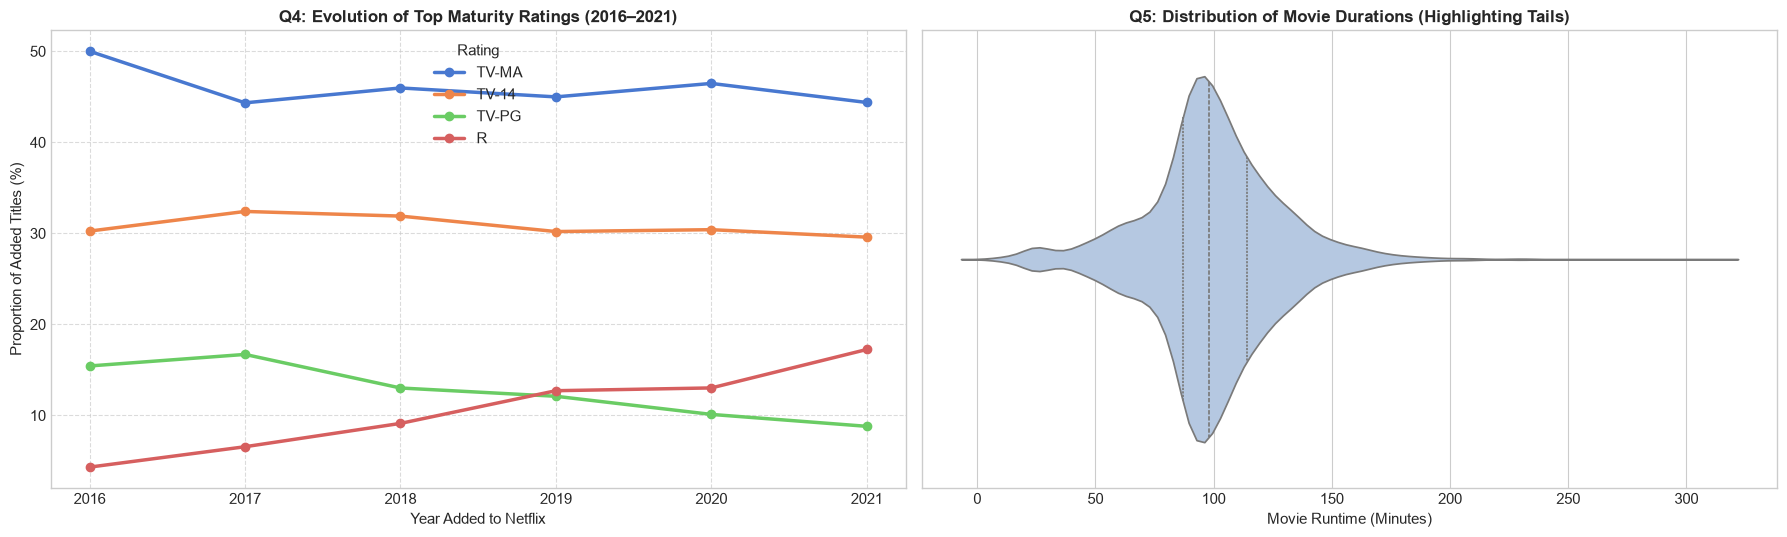

--- Q5: Shortest 5 Movies (Minutes) ---


,title,release_year,duration_int,listed_in
3777,Silent,2014,3,"Children & Family Movies, Sci-Fi & Fantasy"
2713,Sol Levante,2020,5,"Action & Adventure, Anime Features, Internatio..."
1484,Cops and Robbers,2020,8,Dramas
1557,Canvas,2020,9,"Children & Family Movies, Dramas"
3535,American Factory: A Conversation with the Obamas,2019,10,Documentaries



--- Q5: Longest 5 Movies (Minutes) ---


,title,release_year,duration_int,listed_in
4253,Black Mirror: Bandersnatch,2018,312,"Dramas, International Movies, Sci-Fi & Fantasy"
717,Headspace: Unwind Your Mind,2021,273,Documentaries
2491,The School of Mischief,1973,253,"Comedies, Dramas, International Movies"
2487,No Longer kids,1979,237,"Comedies, Dramas, International Movies"
2484,Lock Your Girls In,1982,233,"Comedies, International Movies, Romantic Movies"



--- Q5: TV Shows with >= 10 Seasons ---


,title,release_year,duration_int,listed_in
548,Grey's Anatomy,2020,17,"Romantic TV Shows, TV Dramas"
2423,Supernatural,2019,15,"Classic & Cult TV, TV Action & Adventure, TV H..."
4798,NCIS,2017,15,"Crime TV Shows, TV Dramas, TV Mysteries"
7847,Red vs. Blue,2015,13,"TV Action & Adventure, TV Comedies, TV Sci-Fi ..."
4220,COMEDIANS of the world,2019,13,"Stand-Up Comedy & Talk Shows, TV Comedies"
1354,Heartland,2019,13,TV Dramas
5412,Criminal Minds,2017,12,"Crime TV Shows, TV Dramas, TV Mysteries"
4964,Trailer Park Boys,2018,12,"Classic & Cult TV, Crime TV Shows, Internation..."


In [18]:
# Cell 35: Answering Netflix Analytical Questions 4 and 5

fig, axes = plt.subplots(1, 2, figsize=(18, 5.5))

# -------------------------------------------------------------------------
# Q4: Maturity Ratings Evolution Over Time (Year Added)
# -------------------------------------------------------------------------
# Focus on top 4 primary ratings
top_ratings = ['TV-MA', 'TV-14', 'TV-PG', 'R']
rating_time_df = df_netflix_clean[
    (df_netflix_clean['year_added'].between(2016, 2021)) & 
    (df_netflix_clean['rating'].isin(top_ratings))
]

rating_time_ct = pd.crosstab(rating_time_df['year_added'], rating_time_df['rating'], normalize='index') * 100

for rating in top_ratings:
    axes[0].plot(rating_time_ct.index.astype(int), rating_time_ct[rating], marker='o', linewidth=2.5, label=rating)

axes[0].set_title("Q4: Evolution of Top Maturity Ratings (2016–2021)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Year Added to Netflix", fontsize=11)
axes[0].set_ylabel("Proportion of Added Titles (%)", fontsize=11)
axes[0].set_xticks(range(2016, 2022))
axes[0].grid(True, linestyle='--', alpha=0.7)
axes[0].legend(title="Rating")

# -------------------------------------------------------------------------
# Q5: Movie Duration & TV Seasons - Identification of Extreme Cases
# -------------------------------------------------------------------------
# Violin plot of Movie runtimes showing distribution and outlier tails
sns.violinplot(x=df_netflix_clean[df_netflix_clean['type']=='Movie']['duration_int'], ax=axes[1], color='#aec7e8', inner='quartile')
axes[1].set_title("Q5: Distribution of Movie Durations (Highlighting Tails)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Movie Runtime (Minutes)", fontsize=11)

plt.tight_layout()
plt.show()

# -------------------------------------------------------------------------
# Identify Extreme / Unusual Cases for Q5
# -------------------------------------------------------------------------
print("--- Q5: Shortest 5 Movies (Minutes) ---")
display(df_netflix_clean[df_netflix_clean['type'] == 'Movie'][['title', 'release_year', 'duration_int', 'listed_in']].sort_values(by='duration_int').head(5))

print("\n--- Q5: Longest 5 Movies (Minutes) ---")
display(df_netflix_clean[df_netflix_clean['type'] == 'Movie'][['title', 'release_year', 'duration_int', 'listed_in']].sort_values(by='duration_int', ascending=False).head(5))

print("\n--- Q5: TV Shows with >= 10 Seasons ---")
display(df_netflix_clean[df_netflix_clean['type'] == 'TV Show'][['title', 'release_year', 'duration_int', 'listed_in']].sort_values(by='duration_int', ascending=False).head(8))

* **Question 4: Maturity Rating Distributions and Temporal Trajectory:**
  * **Observation:** Adult programming dominates the catalogue. `TV-MA` consistently remains the largest maturity classification across all additions between 2016 and 2021, holding steady at **45% to 50%** annually[cite: 15]. `TV-14` is the second-largest category, stable around **30% to 32%**[cite: 15]. Titles rated `R` grew steadily from under **5%** in 2016 to over **17%** in 2021[cite: 15]. Conversely, family-oriented content (`TV-PG`) experienced a gradual contraction from **16%** to **9%**[cite: 15].
  * **Interpretation:** Netflix intentionally skewed content acquisition toward adolescent and adult demographics (`TV-MA` + `TV-14` combined comprise >75% of library flow) to maximize prime-time adult subscriber engagement. The surge in `R`-rated titles post-2018 mirrors studio output deals for mature theatrical releases.

* **Question 5: Duration Distributions, Unusual Cases, and Data Treatment:**
  * **Observation:** 
    * **Shortest Movies:** Extreme short-duration outliers include animated shorts and short-form documentaries: *Silent* (3 min), *Sol Levante* (5 min), *Cops and Robbers* (8 min), and *Canvas* (9 min).
    * **Longest Movies:** Extreme high-runtime outliers include interactive branching-narrative titles like *Black Mirror: Bandersnatch* (312 min) and meditation streams like *Headspace: Unwind Your Mind* (273 min), alongside classic Arabic theatrical productions (*The School of Mischief*, 253 min; *No Longer kids*, 237 min).
    * **TV Shows:** While 67% of shows have only 1 season, exceptional multi-season legacy acquisitions reach extreme longevity: *Grey's Anatomy* (17 seasons), *Supernatural* (15 seasons), and *NCIS* (15 seasons).
  * **Treatment & Cleaning Decision:** These extreme records are genuine representations of non-standard media (interactive gaming-narrative hybrids, animated short films, and long-running legacy broadcast syndications) rather than data entry corruptions. They are retained without artificial truncation or clipping to preserve true catalogue variety for downstream analysis[cite: 3].

---

## A8. Netflix Insights and Handoff

### Five Key Evidence-Backed Insights

1. **Format Stratification and the Streaming Pivot**
   * *Observation:* Movies constitute 69.6% (6,131 titles) of the total Netflix catalogue[cite: 9]. However, the proportion of TV Shows added annually expanded from a low of 25.0% in 2018 to 33.7% in 2021[cite: 14].
   * *Interpretation:* Netflix's initial library expansion prioritized rapid volume acquisition through bulk film licensing. As the platform matured, investment shifted toward serialized episodic content.
   * *Speculation:* (Unconfirmed by data) This pivot likely stems from higher customer lifetime value and lower subscriber cancellation rates associated with weekly serialized viewing compared to one-off film viewing.

2. **Ingestion Latency and the Contemporary Catalogue Paradigm**
   * *Observation:* Over 36.9% of all titles were ingested onto Netflix in their original release year, and 68.6% within three years of release[cite: 14]. Titles released prior to 2000 make up only 5% of the library[cite: 9].
   * *Interpretation:* Netflix does not operate as an archival cinematic repository; its catalogue acquisition pipeline is structured around contemporary, fast-turnaround licensed content and immediate in-house productions.

3. **Geographic Specialization across Global Production Hubs**
   * *Observation:* While the United States leads overall volume (3,690 production associations), individual country profiles diverge sharply in genre focus: 49.7% of Indian titles are Dramas and 24.2% are Comedies, whereas the UK features the highest share of Documentaries (19.2%) and Canada leads in Children & Family content (19.3%)[cite: 11, 14].
   * *Interpretation:* Global acquisitions follow regional market strengths, acquiring narrative feature films from Bollywood and Nollywood while sourcing non-fiction documentaries and kids' animation from Commonwealth markets.

4. **Audience Maturity Polarization**
   * *Observation:* Combined, mature titles (`TV-MA` and `TV-14`) represent over 75% of the total streaming additions between 2016 and 2021, with `TV-MA` remaining the single largest category (~45–50% annually)[cite: 15]. Concurrently, `R`-rated movies grew from <5% to >17%[cite: 15].
   * *Interpretation:* Netflix's programming deliberately targets adult and older teen demographics to anchor household subscription accounts.

5. **Serialization Longevity and Production Attrition**
   * *Observation:* 67.0% of all TV series conclude or are cancelled after exactly 1 season, and 82.9% conclude within 2 seasons[cite: 10]. Only 3.9% of shows survive to season 5 or beyond[cite: 10].
   * *Interpretation:* Serialized streaming television exhibits steep commercial survival hurdles; series that do not demonstrate immediate audience traction in their debut season face rapid cancellation.

---

### Handoff Note for Assignment 3 (Feature Selection & Dimensionality Reduction)
**Word Count:** 142 words  
*For Assignment 3, `type`, `release_year`, `year_added`, `duration_int`, `country_count`, and `genre_count` represent high-signal, cleanly formatted features for downstream clustering and classification. High-cardinality semi-structured text columns (`director`, `cast`, `description`) and unique identifiers (`show_id`, `title`) should not be treated as raw features; they require target encoding, TF-IDF, or exclusion to avoid extreme dimensionality[cite: 3]. Note that `catalog_delay_years` exhibits near-perfect collinearity ($r = -0.98$) with `release_year`, meaning one must be eliminated during feature selection to prevent severe multicollinearity[cite: 13]. Imputations of `'Unknown'` in `director`, `cast`, and `country` must be encoded as explicit categorical levels or handled through frequency thresholding so that sparse dummy matrices do not destabilize dimensionality reduction algorithms (e.g., PCA)[cite: 3].*